# 04 - Cross-check high-flow days against NOAA flood reports

Compare observed discharge with NOAA **Flood** and **Flash Flood** reports for the counties containing our three gauges. This is an exploratory check of date overlap, not a set of verified basin flood labels.

- Tuckahoe River: Cape May County, New Jersey (state FIPS 34, county FIPS 009).
- Bear Creek: Adams County, Illinois (17, 001).
- Little North Santiam River: Marion County, Oregon (41, 047).

The county assignments come from [USGS station metadata](https://waterservices.usgs.gov/nwis/site/?format=rdb&sites=01411300,05495500,14182500&siteOutput=expanded). Only county-coded reports (`CZ_TYPE = C`) are matched; forecast-zone codes are not county FIPS codes.

## What counts as an overlap?

For each river, calculate the 95th percentile of observed discharge during the training origin-date window, 1990-01-01 through 2009-12-30. A high-flow day exceeds that fixed threshold. A same-date overlap falls between a NOAA report's start and end calendar dates, inclusive. We also record whether high flow occurs within one day before or after that interval.

NOAA times use local time. This first check compares calendar dates without claiming exact hourly alignment with Caravan. Missing discharge stays unknown. A county report may concern another river or street flooding; no report does not prove there was no flood. Multiple event records may belong to one storm.

Use 1996-2014 because the consistently classified NOAA event archive starts in 1996 and the selected discharge observations stop during 2014. [NOAA archive information](https://www.weather.gov/unr/storm_reports).


In [1]:
from pathlib import Path
import runpy
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent

workflow = runpy.run_path(
    str(ROOT / "caravan_dataset_analysis" / "crosscheck_noaa_floods.py")
)


## Load the NOAA subset

The saved subset contains NOAA's original fields plus the source URL. The source manifest records all 19 annual files, retrieval times, checksums, and record counts. If both cached files are present and match, this step does not download again. The initial download reads the annual national tables and saves only Flood/Flash Flood records for our three gauge counties.


In [2]:
reports = workflow["load_reports"]()
print("County flood-report records:", len(reports))
display(reports.groupby(["STATE", "CZ_NAME", "EVENT_TYPE"]).size().rename("records").to_frame())


County flood-report records: 55


records
STATE      CZ_NAME  EVENT_TYPE          
ILLINOIS   ADAMS    Flash Flood       15
                    Flood              7
NEW JERSEY CAPE MAY Flash Flood       11
                    Flood              5
OREGON     MARION   Flood             17

## Compare the dates and draw the three-basin plot

Orange dots show high-flow observations. Red dots show high flow on days covered by a county flood report. The two tracks near the bottom of each panel show reported Flood and Flash Flood dates separately. The tracks still show reports when discharge is missing.


          basin              county  threshold_mm_day  county_flood_records  county_flash_flood_records  records_with_observed_discharge  records_with_same_date_high_flow  records_with_high_flow_within_one_day  records_naming_river  observed_days  high_flow_days  high_flow_days_with_county_report  high_flow_days_without_county_report  county_report_days_with_flow_below_threshold  county_report_days_without_discharge
camels_01411300 Cape May County, NJ            3.0700                     5                          11                               15                                 6                                      6                     0           6686             348                                  5                                   343                                            11                                     1
camels_05495500    Adams County, IL            3.4655                     7                          15                               22                        

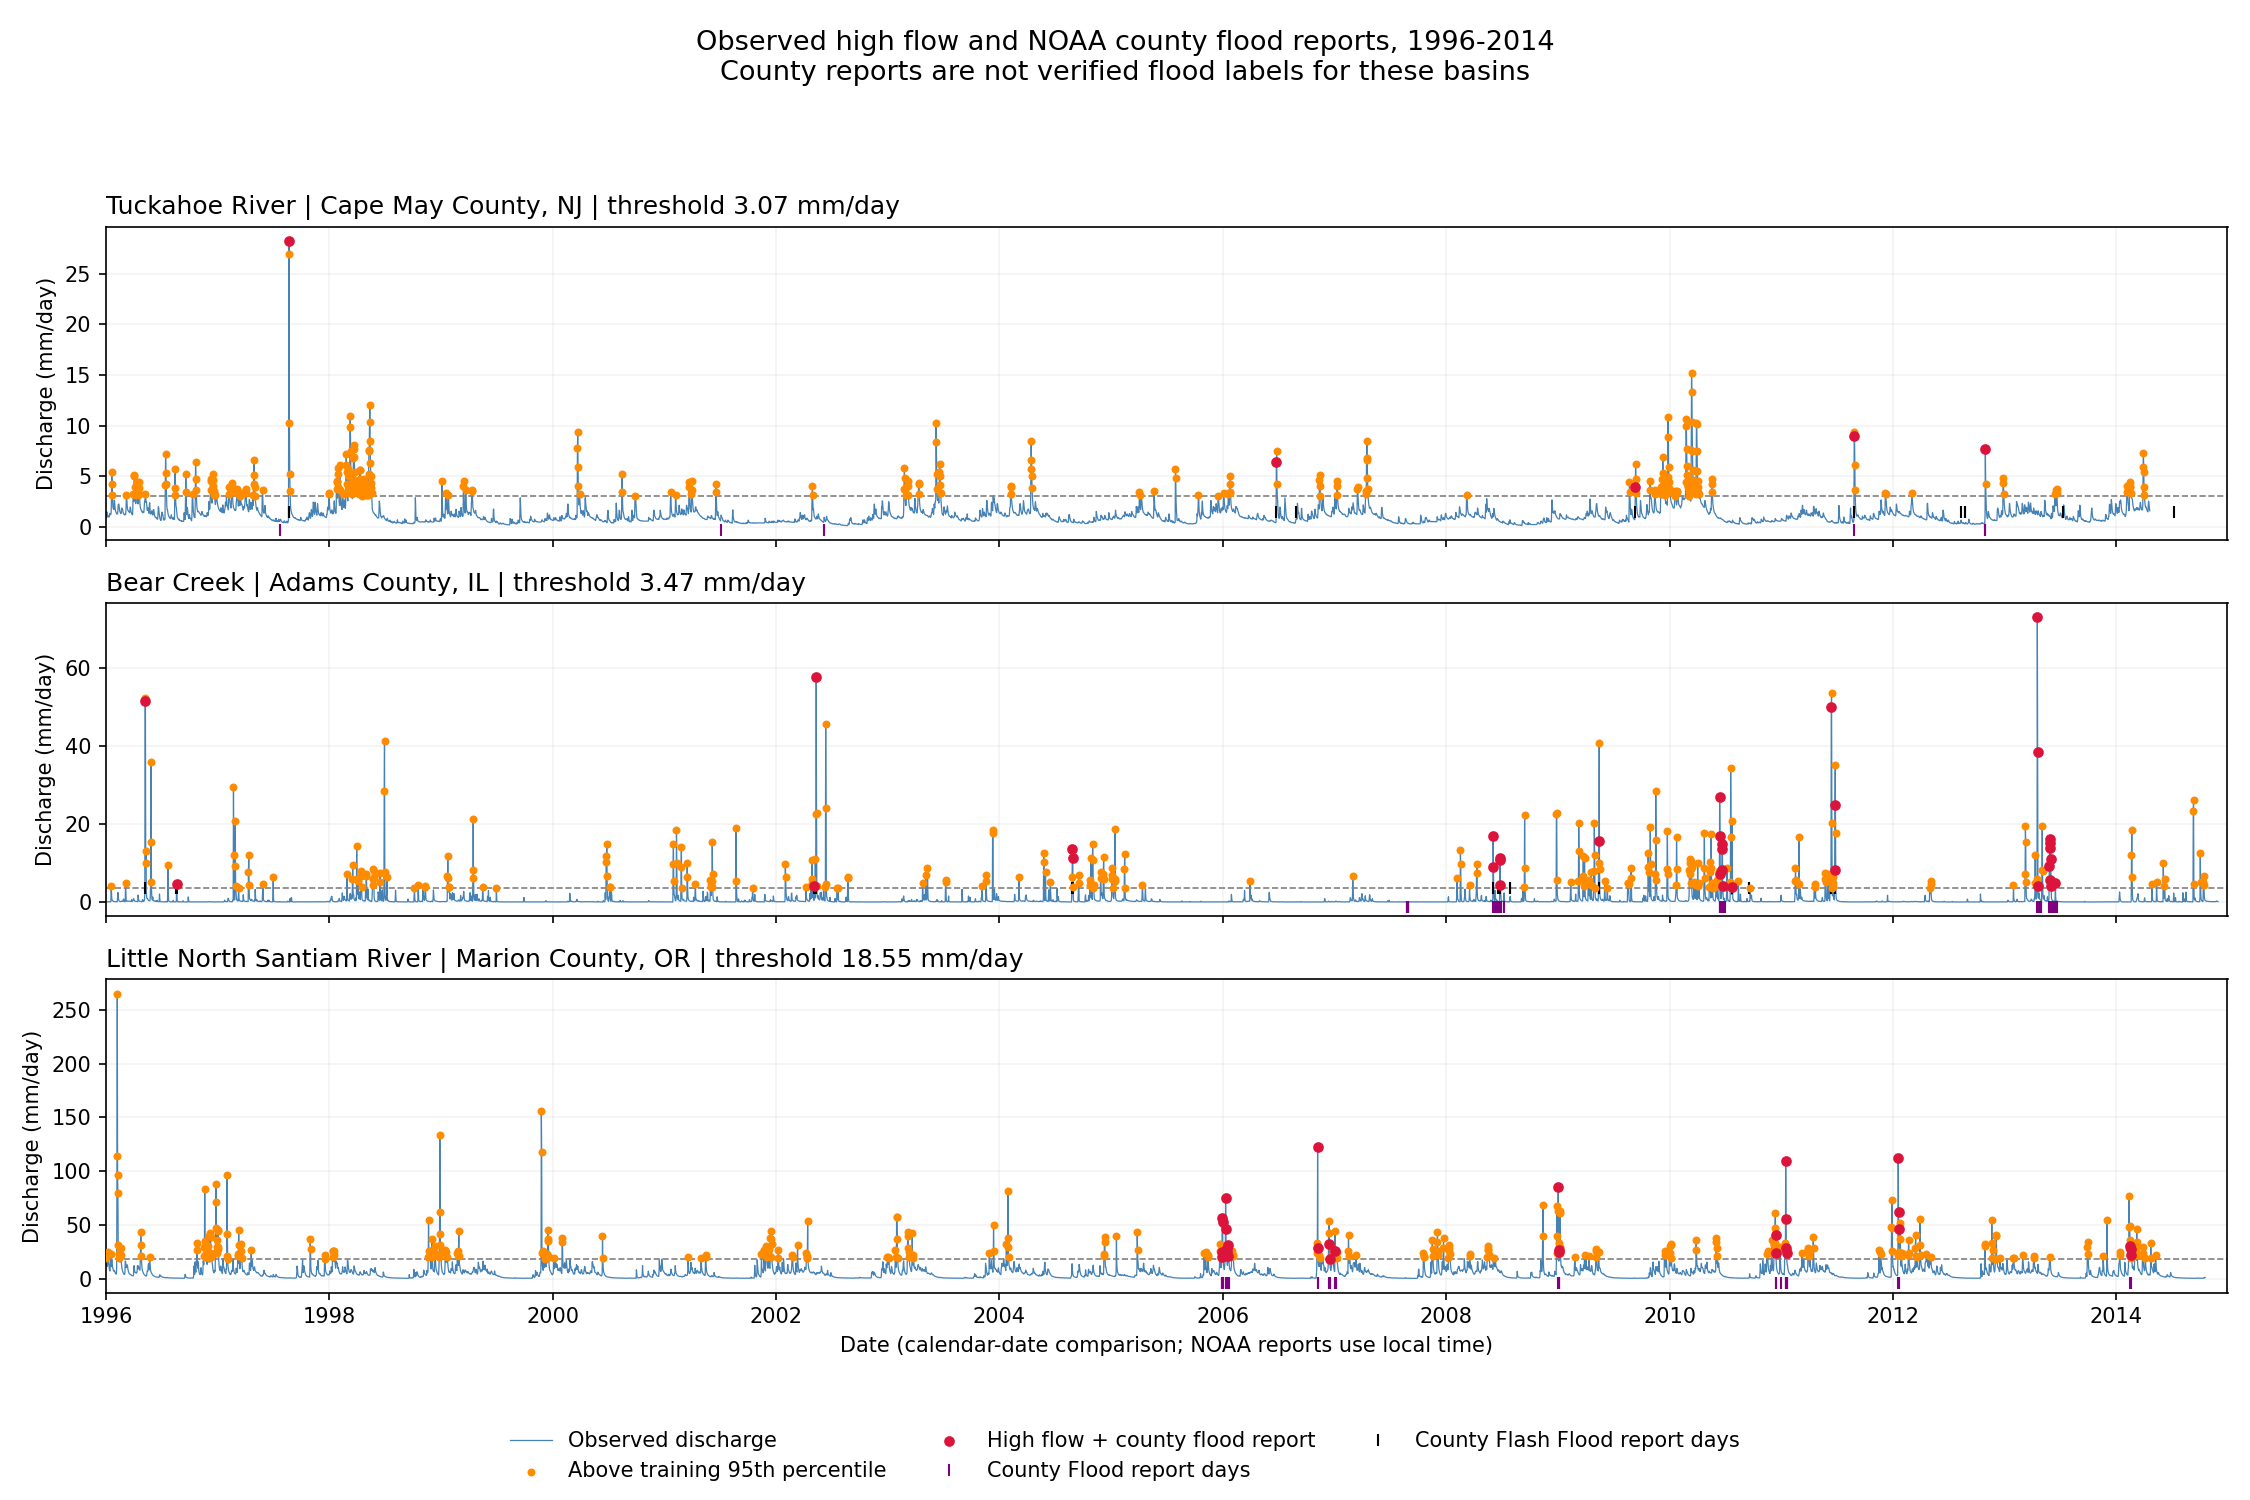

,basin,county,threshold_mm_day,county_flood_records,county_flash_flood_records,records_with_same_date_high_flow,records_with_high_flow_within_one_day,records_naming_river
0,camels_01411300,"Cape May County, NJ",3.070,5,11,6,6,0
1,camels_05495500,"Adams County, IL",3.465,7,15,16,17,1
2,camels_14182500,"Marion County, OR",18.548,17,0,16,17,0


In [3]:
daily_comparison, event_matches, basin_summary = workflow["compare_reports"](reports)

display(basin_summary[[
    "basin", "county", "threshold_mm_day",
    "county_flood_records", "county_flash_flood_records",
    "records_with_same_date_high_flow",
    "records_with_high_flow_within_one_day",
    "records_naming_river"
]].round(3))


## Inspect individual dates and narratives

Start with reports whose event narrative names the selected river. The name flag is a text search for review, not proof of location. Read the narrative and compare the reported locations with the catchment before treating a report as a basin label. The CSV preserves both event and broader storm-episode narratives.


In [4]:
columns = [
    "basin", "event_id", "event_type", "begin_date", "end_date",
    "same_date_high_flow_days", "high_flow_within_one_day",
    "peak_discharge", "peak_date", "river_named_in_event_narrative",
    "begin_location", "event_narrative", "source_url"
]

display(event_matches.loc[
    event_matches["river_named_in_event_narrative"], columns
])

display(event_matches.loc[
    event_matches["same_date_high_flow_days"].gt(0), columns
].sort_values("peak_discharge", ascending=False).head(12))


,basin,event_id,event_type,begin_date,end_date,same_date_high_flow_days,high_flow_within_one_day,peak_discharge,peak_date,river_named_in_event_narrative,begin_location,event_narrative,source_url
26,camels_05495500,123444,Flash Flood,2008-06-18,2008-06-18,0,False,0.18,2008-06-18,True,MEYER,A levee on the Mississippi River near Meyer fa...,https://www.ncei.noaa.gov/pub/data/swdi/storme...


,basin,event_id,event_type,begin_date,end_date,same_date_high_flow_days,high_flow_within_one_day,peak_discharge,peak_date,river_named_in_event_narrative,begin_location,event_narrative,source_url
43,camels_14182500,4698,Flood,2006-11-07,2006-11-08,2,True,122.35,2006-11-07,False,JEFFERSON,The Santiam River near Jefferson crested at 15...,https://www.ncei.noaa.gov/pub/data/swdi/storme...
52,camels_14182500,357148,Flood,2012-01-19,2012-01-20,2,True,112.22,2012-01-19,False,ROBERTS,Widespread low-land flooding occurred in Mario...,https://www.ncei.noaa.gov/pub/data/swdi/storme...
51,camels_14182500,278644,Flood,2011-01-16,2011-01-16,1,True,109.69,2011-01-16,False,MEHAMA,Heavy rain combined with snowmelt runoff to pr...,https://www.ncei.noaa.gov/pub/data/swdi/storme...
46,camels_14182500,146507,Flood,2009-01-02,2009-01-03,2,True,85.22,2009-01-02,False,JEFFERSON,Heavy rain caused the Santiam River near Jeffe...,https://www.ncei.noaa.gov/pub/data/swdi/storme...
41,camels_14182500,5485920,Flood,2006-01-10,2006-01-14,5,True,75.35,2006-01-10,False,AURORA,NaN,https://www.ncei.noaa.gov/pub/data/swdi/storme...
37,camels_05495500,455700,Flood,2013-04-18,2013-04-30,3,True,73.11,2013-04-18,False,MEYER,The Mississippi River reached major flood leve...,https://www.ncei.noaa.gov/pub/data/swdi/storme...
53,camels_14182500,356980,Flood,2012-01-20,2012-01-21,2,True,61.51,2012-01-20,False,ORVILLE,Heavy rain caused the Willamette River at Sale...,https://www.ncei.noaa.gov/pub/data/swdi/storme...
19,camels_05495500,5291597,Flash Flood,2002-05-12,2002-05-12,1,True,57.68,2002-05-12,False,COUNTYWIDE,NaN,https://www.ncei.noaa.gov/pub/data/swdi/storme...
38,camels_14182500,5489129,Flood,2005-12-28,2005-12-31,4,True,56.62,2005-12-30,False,JEFFERSON,NaN,https://www.ncei.noaa.gov/pub/data/swdi/storme...
39,camels_14182500,5489124,Flood,2005-12-28,2005-12-31,4,True,56.62,2005-12-30,False,AURORA,NaN,https://www.ncei.noaa.gov/pub/data/swdi/storme...


## Saved outputs and limits

Outputs are in `results/noaa_crosscheck/`:

- `basin_summary.csv`: report counts and overlap totals by river.
- `event_matches.csv`: one row per county report, with dates, observed flow, narratives, and source links.
- `daily_comparison.csv`: one row per basin-day, retaining missing discharge as unknown.
- `noaa_flood_high_flow_comparison.png`: the combined three-panel plot.

This comparison uses observed flow, not model predictions. It does not measure forecast accuracy, establish an official flood threshold, or count unmatched high-flow days as false alarms. The threshold is fitted on 1990-2009 observations; the full 1996-2014 summary is descriptive. Use later test dates separately for model evaluation, and obtain reviewed basin event labels before scoring actual flood detection.

County screening can miss upstream events reported in neighboring counties. Forecast-zone-coded reports and coastal flooding are excluded. A further geographic check needs catchment boundaries and the event locations; the USGS basin service was unavailable during this initial analysis.
